# 09. 중간발표 기초통계량
모델 코호트(안전센터, 2019~2024)의 분할별 기초통계량. 2025 시험 구간은 열지 않았다. 입력 `data/splits/`(커밋 금지), 출력 `발표자료/중간발표/표/`.

In [1]:
import os
from pathlib import Path

if Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
import pandas as pd

SP = Path("data/splits/train2019-2022_calib1-12")
TBL = Path("발표자료/중간발표/표")
NAME = {"train": "학습 (2019-2022)", "valid": "검증 (2023)", "calib": "보정 (2024)"}
df = pd.concat([pd.read_parquet(SP / f"{s}.parquet").assign(split=s) for s in NAME])
df.groupby("split").size()

split
calib     528744
train    1275974
valid     421592
dtype: int64

In [2]:
def summarize(g: pd.DataFrame) -> pd.Series:
    d = g.dist_km.astype(float)
    return pd.Series({
        "건수": len(g),
        "안전센터 수": g.center_id.nunique(),
        "8분 초과율(%)": g.y_late.mean() * 100,
        "도착 소요 평균(분)": g.resp_min.mean(),
        "도착 소요 중앙값(분)": g.resp_min.median(),
        "도착 소요 표준편차(분)": g.resp_min.std(),
        "도착 소요 90분위(분)": g.resp_min.quantile(0.9),
        "출동 거리 평균(km)": d.mean(),
        "출동 거리 중앙값(km)": d.median(),
        "출동 거리 결측(%)": d.isna().mean() * 100,
        "6km 초과(%)": g.out_of_range.astype(float).mean() * 100,
        "관외출동(%)": g.out_of_jur.astype(float).mean() * 100,
        "공휴일(%)": g.is_holiday.astype(float).mean() * 100,
    })

tab = pd.concat({NAME[s]: summarize(df[df.split == s]) for s in NAME} | {"합계 (2019-2024)": summarize(df)}, axis=1)
tab.loc["비율(%)"] = tab.loc["건수"] / len(df) * 100
tab = tab.round(2)
tab.to_csv(TBL / "기초통계_안전센터_분할별.csv", encoding="utf-8-sig")
tab

,학습 (2019-2022),검증 (2023),보정 (2024),합계 (2019-2024)
건수,1275974.00,421592.00,528744.00,2226310.00
안전센터 수,242.00,122.00,160.00,293.00
8분 초과율(%),41.07,42.57,48.25,43.06
도착 소요 평균(분),9.18,8.80,8.78,9.01
도착 소요 중앙값(분),8.00,8.00,8.00,8.00
도착 소요 표준편차(분),6.76,4.76,4.83,6.00
도착 소요 90분위(분),14.00,13.00,13.18,13.98
출동 거리 평균(km),2.00,1.81,1.85,1.93
출동 거리 중앙값(km),2.00,2.00,1.70,2.00
출동 거리 결측(%),0.01,0.00,0.10,0.03


In [3]:
yr = df.groupby("year").agg(건수=("y_late", "size"), 초과율=("y_late", "mean"), 소요중앙값=("resp_min", "median"), 거리중앙값=("dist_km", "median"), 관외=("out_of_jur", "mean"))
yr[["초과율", "관외"]] *= 100
yr = yr.round(2)
yr.to_csv(TBL / "기초통계_안전센터_연도별.csv", encoding="utf-8-sig")
yr

,건수,초과율,소요중앙값,거리중앙값,관외
year,,,,,
2019,181474,20.74,6.0,1.0,18.89
2020,340254,35.86,7.0,2.0,21.02
2021,371444,46.04,8.0,2.0,25.77
2022,382802,50.52,9.0,2.0,26.38
2023,421592,42.57,8.0,2.0,21.36
2024,528744,48.25,8.0,1.7,19.08


## 질문별 변수 기초통계 (2024)
연구 질문마다 쓰는 변수의 분포. 라벨·거리·관외출동은 안전센터 2024(보정 구간), 신고 몰림·속도·강수는 서울 2024 코호트(제안발표 EDA 집계).

In [4]:
cal = df[df.split == "calib"]
m = pd.read_parquet("work/ref/eda_multivar.parquet")
rain = pd.read_csv("results/rain_join_2024.csv", encoding="utf-8-sig")


def row(q, var, target, s):
    s = pd.Series(s, dtype=float)
    return {"질문": q, "변수": var, "대상": target, "건수": int(s.notna().sum()),
            "평균": s.mean(), "중앙값": s.median(), "10분위": s.quantile(.1), "90분위": s.quantile(.9),
            "결측(%)": s.isna().mean() * 100}


rows = [
    row("Q0 라벨", "도착 소요시간(분)", "안전센터 2024", cal.resp_min),
    row("Q0 라벨", "8분 초과(0/1)", "안전센터 2024", cal.y_late),
    row("Q0 기본", "출동 거리(km)", "안전센터 2024", cal.dist_km),
    row("자문 관외출동", "관외출동(0/1)", "안전센터 2024", cal.out_of_jur),
    row("Q1 신고 몰림", "구 직전 60분 신고 건수", "서울 2024", m.sgg_load),
    row("Q1 신고 몰림", "센터 직전 60분 출동 건수", "서울 2024", m.center_load),
    row("Q2 교통 정체", "구 평균 속도(km/h)", "서울 2024", m.avg_speed_kmh),
]
qs = pd.DataFrame(rows)
n_rain = rain.calls.sum()
wet = rain[rain.rain_bin != "0mm"].calls.sum()
over5 = rain[rain.rain_bin == "5초과"].calls.sum()
qs = pd.concat([qs, pd.DataFrame([
    {"질문": "날씨", "변수": "3시간 누적 강수 있음(0/1)", "대상": "서울 2024", "건수": n_rain, "평균": wet / n_rain},
    {"질문": "날씨", "변수": "3시간 누적 강수 5mm 초과(0/1)", "대상": "서울 2024", "건수": n_rain, "평균": over5 / n_rain},
])], ignore_index=True)
qs = qs.round(3)
qs.to_csv(TBL / "기초통계_질문별변수_2024.csv", index=False, encoding="utf-8-sig")
qs

,질문,변수,대상,건수,평균,중앙값,10분위,90분위,결측(%)
0,Q0 라벨,도착 소요시간(분),안전센터 2024,528744,8.781,8.000,4.933,13.183,0.000
1,Q0 라벨,8분 초과(0/1),안전센터 2024,528744,0.482,0.000,0.000,1.000,0.000
2,Q0 기본,출동 거리(km),안전센터 2024,528239,1.847,1.700,0.700,3.000,0.096
3,자문 관외출동,관외출동(0/1),안전센터 2024,528692,0.191,0.000,0.000,1.000,0.010
4,Q1 신고 몰림,구 직전 60분 신고 건수,서울 2024,550030,3.102,3.000,1.000,6.000,0.000
5,Q1 신고 몰림,센터 직전 60분 출동 건수,서울 2024,550030,0.531,0.000,0.000,2.000,0.000
6,Q2 교통 정체,구 평균 속도(km/h),서울 2024,548907,25.716,25.139,21.025,31.321,0.204
7,날씨,3시간 누적 강수 있음(0/1),서울 2024,550251,0.107,NaN,NaN,NaN,NaN
8,날씨,3시간 누적 강수 5mm 초과(0/1),서울 2024,550251,0.026,NaN,NaN,NaN,NaN


## 질문별 EDA 4패널
노트북 08의 4패널을 중간발표 질문(Q0·관외출동·날씨·Q1×Q2) 이름으로 다시 그림. 새 분석 없음.

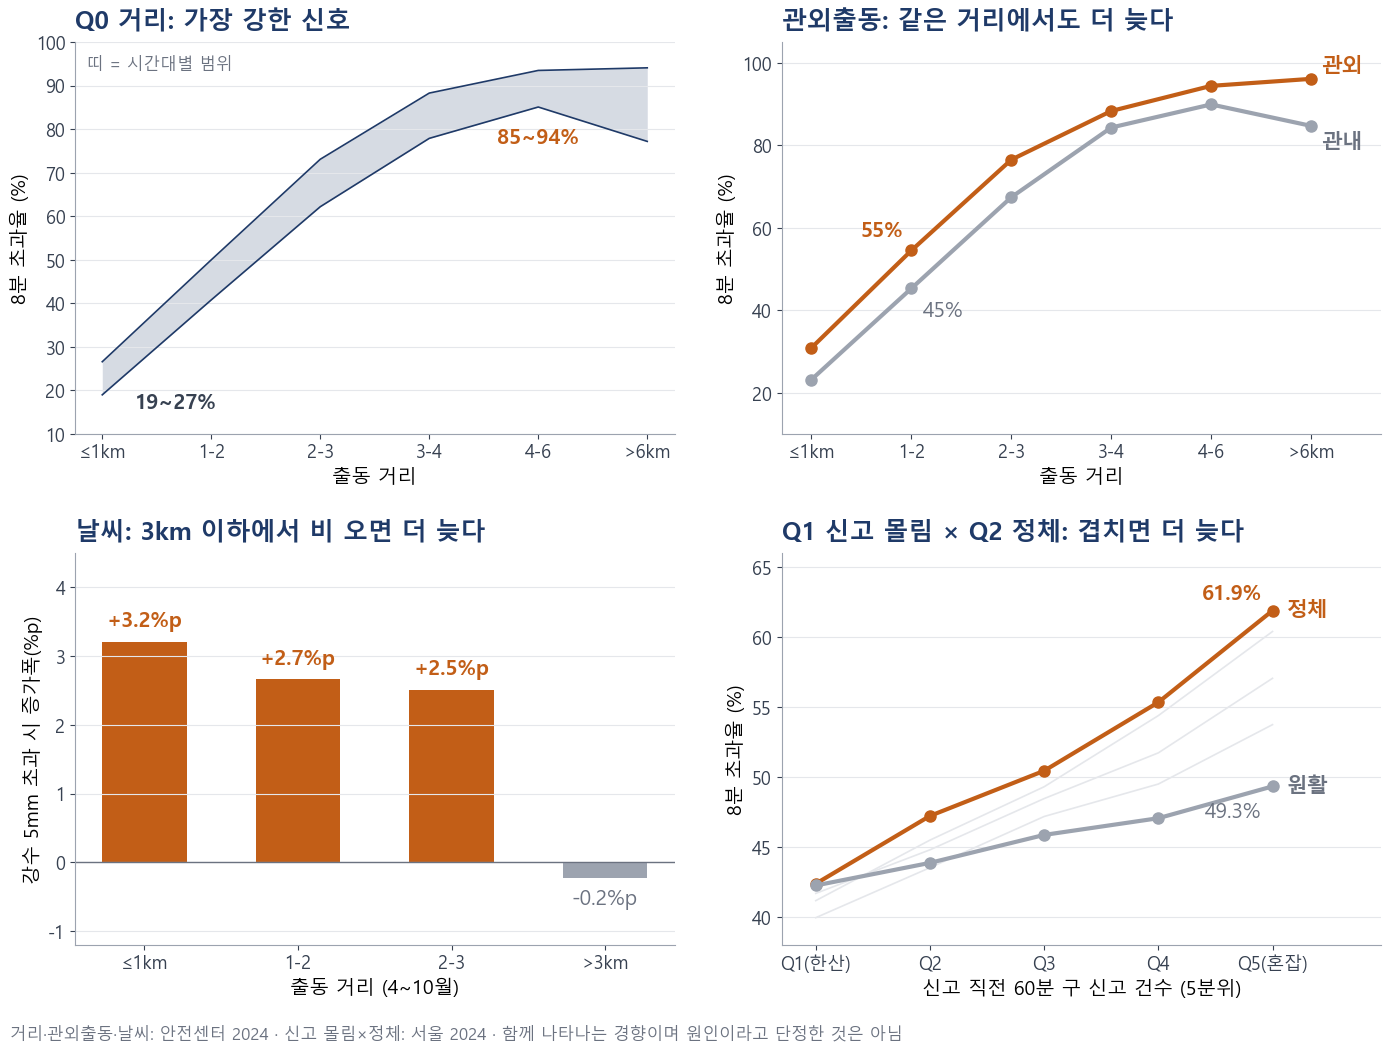

In [6]:
T = Path("발표자료/중간발표/표")
dt = pd.read_csv(T / "EDA_Q1_거리x시간대.csv", encoding="utf-8-sig").set_index("dbin") * 100
dist = pd.read_csv(T / "EDA_Q1_거리x관외.csv", encoding="utf-8-sig")
dist[["관내", "관외"]] = dist[["관내", "관외"]] * 100
rn = pd.read_csv(T / "EDA_Q3_거리x강수_층화.csv", encoding="utf-8-sig")
rn = rn[rn["계절"] == "4~10월"].reset_index(drop=True)
ok = m["dist_km"].isna() | m["dist_km"].between(0, 100)
dx = m[ok].dropna(subset=["avg_speed_kmh"]).copy()
dx["load_q"] = pd.qcut(dx["sgg_load"], 5, labels=["Q1(한산)", "Q2", "Q3", "Q4", "Q5(혼잡)"])
dx["speed_q"] = pd.qcut(dx["avg_speed_kmh"], 5, labels=["S1(정체)", "S2", "S3", "S4", "S5(원활)"])
cross = dx.pivot_table(index="load_q", columns="speed_q", values="late", aggfunc="mean", observed=True) * 100
lo, hi = dt.min(axis=1), dt.max(axis=1)

fig, axs = plt.subplots(2, 2, figsize=(14, 10.5))
(a1, a2), (a3, a4) = axs
TS, LS, KS, AS = 18, 14, 13, 15
x = list(range(len(dt)))
a1.fill_between(x, lo.values, hi.values, color=NAVY, alpha=0.18, lw=0)
a1.plot(x, lo.values, color=NAVY, lw=1.2)
a1.plot(x, hi.values, color=NAVY, lw=1.2)
a1.set_xticks(x, dt.index)
a1.set_ylim(10, 100)
a1.text(0.3, 16, f"{lo.iloc[0]:.0f}~{hi.iloc[0]:.0f}%", fontsize=AS, color=TXT, fontweight="bold")
i46 = list(dt.index).index("4-6")
a1.annotate(f"{lo.iloc[i46]:.0f}~{hi.iloc[i46]:.0f}%", (i46, lo.iloc[i46]), textcoords="offset points", xytext=(0, -26), ha="center", fontsize=AS, color=ORANGE, fontweight="bold")
a1.text(0.02, 0.93, "띠 = 시간대별 범위", transform=a1.transAxes, fontsize=KS - 1, color="#6B7280")
a1.set_title("Q0 거리: 가장 강한 신호", fontsize=TS, fontweight="bold", color=NAVY, loc="left", pad=10)
a1.set_xlabel("출동 거리", fontsize=LS)

xd = list(range(len(dist)))
a2.plot(xd, dist["관내"], marker="o", lw=3, ms=8, color=GRAY)
a2.plot(xd, dist["관외"], marker="o", lw=3, ms=8, color=ORANGE)
a2.set_xticks(xd, dist["dbin"])
a2.set_ylim(10, 105)
a2.set_xlim(-0.3, len(dist) - 0.3)
a2.text(len(dist) - 1 + 0.1, dist["관외"].iloc[-1] + 3, "관외", color=ORANGE, fontsize=AS, fontweight="bold", va="center")
a2.text(len(dist) - 1 + 0.1, dist["관내"].iloc[-1] - 4, "관내", color="#6B7280", fontsize=AS, fontweight="bold", va="center")
a2.annotate(f"{dist['관외'].iloc[1]:.0f}%", (1, dist["관외"].iloc[1]), textcoords="offset points", xytext=(-6, 10), ha="right", fontsize=AS, color=ORANGE, fontweight="bold")
a2.annotate(f"{dist['관내'].iloc[1]:.0f}%", (1, dist["관내"].iloc[1]), textcoords="offset points", xytext=(8, -20), ha="left", fontsize=AS, color="#6B7280")
a2.set_title("관외출동: 같은 거리에서도 더 늦다", fontsize=TS, fontweight="bold", color=NAVY, loc="left", pad=10)
a2.set_xlabel("출동 거리", fontsize=LS)

xr = list(range(len(rn)))
vals = rn["차이(%p)"].values
a3.bar(xr, vals, width=0.55, color=[ORANGE if v > 0 else GRAY for v in vals])
a3.axhline(0, color="#6B7280", lw=1)
for i, v in enumerate(vals):
    a3.text(i, v + (0.15 if v > 0 else -0.15), f"{v:+.1f}%p", ha="center", va="bottom" if v > 0 else "top",
            fontsize=AS, color=ORANGE if v > 0 else "#6B7280", fontweight="bold" if v > 0 else "normal")
a3.set_xticks(xr, rn["거리"])
a3.set_ylim(-1.2, 4.5)
a3.set_title("날씨: 3km 이하에서 비 오면 더 늦다", fontsize=TS, fontweight="bold", color=NAVY, loc="left", pad=10)
a3.set_xlabel("출동 거리 (4~10월)", fontsize=LS)
a3.set_ylabel("강수 5mm 초과 시 증가폭(%p)", fontsize=LS)

xs = list(range(len(cross)))
for col in ["S2", "S3", "S4"]:
    a4.plot(xs, cross[col], lw=1.2, color=LIGHT, zorder=0)
a4.plot(xs, cross["S1(정체)"], marker="o", lw=3, ms=8, color=ORANGE)
a4.plot(xs, cross["S5(원활)"], marker="o", lw=3, ms=8, color=GRAY)
a4.set_xticks(xs, cross.index)
a4.set_xlim(-0.3, len(cross) - 0.05)
a4.set_ylim(38, 66)
a4.text(len(cross) - 1 + 0.12, cross["S1(정체)"].iloc[-1], "정체", color=ORANGE, fontsize=AS, fontweight="bold", va="center")
a4.text(len(cross) - 1 + 0.12, cross["S5(원활)"].iloc[-1], "원활", color="#6B7280", fontsize=AS, fontweight="bold", va="center")
a4.annotate(f"{cross['S1(정체)'].iloc[-1]:.1f}%", (len(cross) - 1, cross["S1(정체)"].iloc[-1]), textcoords="offset points", xytext=(-8, 8), ha="right", fontsize=AS, color=ORANGE, fontweight="bold")
a4.annotate(f"{cross['S5(원활)'].iloc[-1]:.1f}%", (len(cross) - 1, cross["S5(원활)"].iloc[-1]), textcoords="offset points", xytext=(-8, -22), ha="right", fontsize=AS, color="#6B7280")
a4.set_title("Q1 신고 몰림 × Q2 정체: 겹치면 더 늦다", fontsize=TS, fontweight="bold", color=NAVY, loc="left", pad=10)
a4.set_xlabel("신고 직전 60분 구 신고 건수 (5분위)", fontsize=LS)

for ax in (a1, a2, a4):
    ax.set_ylabel("8분 초과율 (%)", fontsize=LS)
for ax in axs.flat:
    ax.tick_params(labelsize=KS, colors=TXT)
    ax.grid(axis="y", color=LIGHT, lw=0.8)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_color(GRAY)
fig.text(0.01, 0.005, "거리·관외출동·날씨: 안전센터 2024 · 신고 몰림×정체: 서울 2024 · 함께 나타나는 경향이며 원인이라고 단정한 것은 아님",
         fontsize=12, color="#6B7280")
plt.tight_layout(rect=(0, 0.03, 1, 1), h_pad=2.5, w_pad=3)
plt.savefig(FIG / "3_다변량" / "3-5_질문별_EDA_4패널.png", dpi=200, facecolor="white")
plt.show()

## 질문별 변수 분포 그래프 (S2)
위 기초통계표를 슬라이드용 그래프로. 패널 제목 = 연구 질문. 라벨·거리·관외출동은 안전센터 2024, 신고 몰림·속도·강수는 서울 2024.

In [ ]:
import numpy as np

fig, axs = plt.subplots(2, 3, figsize=(16, 9.5))
TS, LS, KS, AS = 16, 13, 12, 14


def style(ax, title, sub):
    ax.set_title(title, fontsize=TS, fontweight="bold", color=NAVY, loc="left", pad=26)
    ax.text(0, 1.02, sub, transform=ax.transAxes, fontsize=LS - 1, color="#6B7280")
    ax.tick_params(labelsize=KS, colors=TXT)
    ax.grid(axis="y", color=LIGHT, lw=0.8)
    for s in ["top", "right"]:
        ax.spines[s].set_visible(False)
    for s in ["left", "bottom"]:
        ax.spines[s].set_color(GRAY)


a = axs[0, 0]
r = cal.resp_min.clip(upper=30)
cnt, edges = np.histogram(r, bins=range(0, 31))
a.bar(edges[:-1] + 0.5, cnt / len(r) * 100, width=0.9, color=[ORANGE if e >= 8 else NAVY for e in edges[:-1]])
a.axvline(8, color=TXT, lw=1.5, ls="--")
a.text(16, a.get_ylim()[1] * 0.85, f"8분 초과 {cal.y_late.mean():.1%}", fontsize=AS, color=ORANGE, fontweight="bold")
a.text(16, a.get_ylim()[1] * 0.72, f"중앙값 {cal.resp_min.median():.1f}분", fontsize=AS - 1, color=TXT)
a.set_xlabel("도착 소요시간 (분, 30분 이상은 30에 모음)", fontsize=LS)
a.set_ylabel("출동 비율 (%)", fontsize=LS)
style(a, "Q0  무엇을 맞히나: 8분 초과", "안전센터 2024 · 8분이 분포 한가운데")

a = axs[0, 1]
d = cal.dist_km.dropna().clip(upper=8)
cnt, edges = np.histogram(d, bins=np.arange(0, 8.5, 0.5))
a.bar(edges[:-1] + 0.25, cnt / len(d) * 100, width=0.45, color=NAVY)
a.axvline(cal.dist_km.median(), color=ORANGE, lw=2, ls="--")
a.text(4.3, a.get_ylim()[1] * 0.85, f"중앙값 {cal.dist_km.median():.1f}km", fontsize=AS, color=ORANGE, fontweight="bold")
a.set_xlabel("출동 거리 (km, 8km 이상은 8에 모음)", fontsize=LS)
style(a, "Q0  기본 정보: 출동 거리", "안전센터 2024 · 대부분 3km 이내, 정수 km 기재가 많음")

a = axs[0, 2]
oj = cal.out_of_jur.mean() * 100
a.barh(["관내", "관외"], [100 - oj, oj], color=[GRAY, ORANGE], height=0.55)
for i, v in enumerate([100 - oj, oj]):
    a.text(v + 1.5, i, f"{v:.1f}%", va="center", fontsize=AS, color=ORANGE if i else TXT, fontweight="bold")
a.set_xlim(0, 100)
a.set_xlabel("출동 비율 (%)", fontsize=LS)
a.grid(axis="x", color=LIGHT, lw=0.8)
style(a, "관외출동 (1차 자문)", "안전센터 2024 · 5건 중 1건은 관할 밖")
a.grid(axis="y", visible=False)

a = axs[1, 0]
ld = m.sgg_load.clip(upper=12).value_counts(normalize=True).sort_index() * 100
a.bar(ld.index, ld.values, width=0.8, color=NAVY)
a.set_xticks(range(0, 13, 2))
q10, q90 = m.sgg_load.quantile([.1, .9])
a.axvspan(q10 - 0.5, q90 + 0.5, color=ORANGE, alpha=0.08)
a.text(q90 + 0.7, ld.max() * 0.9, f"평균 {m.sgg_load.mean():.1f}건\n10~90%: {q10:.0f}~{q90:.0f}건", fontsize=AS - 1, color=ORANGE, fontweight="bold")
a.set_xlabel("신고 직전 60분 같은 구 신고 건수 (12건 이상은 12에 모음)", fontsize=LS)
a.set_ylabel("출동 비율 (%)", fontsize=LS)
style(a, "Q1  신고 몰림", "서울 2024 · 같은 구라도 시간마다 폭이 큼")

a = axs[1, 1]
sp = m.avg_speed_kmh.dropna()
cnt, edges = np.histogram(sp, bins=np.arange(10, 45, 1))
a.bar(edges[:-1] + 0.5, cnt / len(sp) * 100, width=0.9, color=NAVY)
s10, s90 = sp.quantile([.1, .9])
a.axvspan(s10, s90, color=ORANGE, alpha=0.08)
a.text(33, a.get_ylim()[1] * 0.80, f"평균 {sp.mean():.1f}km/h\n10~90%: {s10:.0f}~{s90:.0f}", fontsize=AS - 1, color=ORANGE, fontweight="bold")
a.set_xlabel("신고 직전 1시간 구 평균 속도 (km/h)", fontsize=LS)
style(a, "Q2  교통 정체", "서울 2024 · 정체 지수의 바탕(평소 속도와 비교)")

a = axs[1, 2]
rb = rain.groupby("rain_bin").calls.sum().reindex(["0mm", "0~1", "1~5", "5초과"])
pct = rb / rb.sum() * 100
labels = ["비 없음", "0~1mm", "1~5mm", "5mm 초과"]
a.bar(labels, pct.values, width=0.6, color=[GRAY, ORANGE, ORANGE, ORANGE])
for i, v in enumerate(pct.values):
    a.text(i, v + 1.5, f"{v:.1f}%", ha="center", fontsize=AS, color=TXT if i == 0 else ORANGE, fontweight="bold")
a.set_ylim(0, 100)
a.set_xlabel("신고 전 3시간 누적 강수", fontsize=LS)
style(a, "날씨", "서울 2024 · 비 온 출동은 10.7%뿐 → 여러 해 자료 필요")

plt.tight_layout(h_pad=3.2, w_pad=2.5)
plt.savefig(FIG / "2_일변량" / "2-8_질문별_변수분포.png", dpi=200, facecolor="white")
plt.show()

## 슬라이드용 표 그림 (S2 기초통계, S4 EDA 결과)
수치는 위에서 계산한 `qs`, `cross`, `dt`, `dist`, `rn`, 연도별 `yr`에서 가져온다. 새 분석 없음.

In [ ]:
def table_figure(head, rows, widths, out, foot, hl_col):
    """질문 열(남색)과 강조 열(주황)을 둔 표 그림을 저장한다."""
    xs = np.concatenate([[0], np.cumsum(np.array(widths) + 0.15)])[:-1]
    total = xs[-1] + widths[-1]
    fig, ax = plt.subplots(figsize=(16, 1.15 * len(rows) + 1.6))
    ax.set_xlim(-0.05, total + 0.05)
    ax.set_ylim(-1.0, len(rows) - 0.05)
    ax.axis("off")
    for x, w, h in zip(xs, widths, head):
        ax.text(x + w / 2, len(rows) - 0.3, h, ha="center", va="center", fontsize=15, fontweight="bold", color=NAVY)
    for i, cells in enumerate(rows):
        y = len(rows) - 1 - i
        for j, (x, w, t) in enumerate(zip(xs, widths, cells)):
            face = NAVY if j == 0 else ("#FBEFE6" if j == hl_col else "white")
            edge = NAVY if j == 0 else (ORANGE if j == hl_col else GRAY)
            ax.add_patch(FancyBboxPatch((x, y - 0.42), w, 0.84, boxstyle="round,pad=0.02,rounding_size=0.08", fc=face, ec=edge, lw=1.3))
            ax.text(x + w / 2, y, t, ha="center", va="center", fontsize=13, linespacing=1.3,
                    color="white" if j == 0 else TXT, fontweight="bold" if j in (0, hl_col) else "normal")
    ax.text(0, -0.75, foot, fontsize=12, color="#6B7280", va="center")
    plt.tight_layout()
    plt.savefig(out, dpi=200, facecolor="white")
    plt.show()


v = qs.set_index("변수")
yr_rate = yr["초과율"]
table_figure(
    ["연구 질문", "데이터 (출처)", "변수", "기초통계 (2024)", "알 수 있는 점"],
    [
        ["Q0  8분 초과\n(맞힐 대상)", "구급 출동 기록\n(소방청)", "도착 소요시간\n8분 초과 여부",
         f"평균 {v.loc['도착 소요시간(분)', '평균']:.2f}분 · 중앙값 {v.loc['도착 소요시간(분)', '중앙값']:.1f}분\n8분 초과 {v.loc['8분 초과(0/1)', '평균']:.1%}",
         "8분이 분포 한가운데\n→ 조건에 따라 갈리는 경계"],
        ["Q0  기본 정보", "구급 출동 기록\n(소방청)", "출동 거리",
         f"평균 {v.loc['출동 거리(km)', '평균']:.2f}km · 중앙값 {v.loc['출동 거리(km)', '중앙값']:.1f}km\n90%가 {v.loc['출동 거리(km)', '90분위']:.0f}km 이내",
         "짧은 거리에 몰림\n정수 km 기재가 많음"],
        ["관외출동\n(1차 자문)", "119안전센터\n관할구역", "관외출동 여부",
         f"관외 {v.loc['관외출동(0/1)', '평균']:.1%}", "5건 중 1건은\n관할 밖 출동"],
        ["Q1  신고 몰림", "구급 출동 기록\n(정제 전 전체)", "구 직전 60분\n신고 건수",
         f"평균 {v.loc['구 직전 60분 신고 건수', '평균']:.1f}건\n10~90%: {v.loc['구 직전 60분 신고 건수', '10분위']:.0f}~{v.loc['구 직전 60분 신고 건수', '90분위']:.0f}건",
         "같은 구라도\n시간마다 폭이 큼"],
        ["Q2  교통 정체", "차량통행속도\n(서울시 TOPIS)", "구 평균 속도",
         f"평균 {v.loc['구 평균 속도(km/h)', '평균']:.1f}km/h\n10~90%: {v.loc['구 평균 속도(km/h)', '10분위']:.0f}~{v.loc['구 평균 속도(km/h)', '90분위']:.0f}km/h",
         "평소 속도와 비교해\n정체 지수로 만듦"],
        ["날씨", "기상 관측\nASOS 108 (기상청)", "3시간 누적 강수",
         f"비 온 출동 {v.loc['3시간 누적 강수 있음(0/1)', '평균']:.1%}\n5mm 초과 {v.loc['3시간 누적 강수 5mm 초과(0/1)', '평균']:.1%}",
         "드물어서\n여러 해 자료가 필요"],
    ],
    [2.3, 2.5, 2.1, 4.4, 3.2],
    FIG / "2_일변량" / "2-9_질문별_기초통계표.png",
    "Q0·관외출동: 안전센터 2024 (528,744건) · Q1·Q2·날씨: 서울 2024 코호트 · 전체 원본: 서울 구급 출동 7년 3,613,740건",
    3,
)

tabl = list(dt.index)
table_figure(
    ["연구 질문", "확인한 것", "결과", "모델에 반영"],
    [
        ["Q0  거리", "거리 구간별\n8분 초과율",
         f"1km 이하 {lo.iloc[0]:.0f}~{hi.iloc[0]:.0f}%\n→ 4~6km {lo.iloc[tabl.index('4-6')]:.0f}~{hi.iloc[tabl.index('4-6')]:.0f}%",
         "가장 강한 신호\n거리 포함·제외 두 설정"],
        ["관외출동\n(1차 자문)", "같은 거리에서\n관내 vs 관외",
         f"관외가 +{(dist['관외'] - dist['관내']).iloc[:5].min():.0f}~{(dist['관외'] - dist['관내']).iloc[:5].max():.0f}%p\n(1~2km: {dist['관내'].iloc[1]:.0f}% → {dist['관외'].iloc[1]:.0f}%)",
         "기본 변수로 넣음"],
        ["날씨", "같은 거리에서\n비 5mm 초과 vs 없음",
         f"3km 이하 +{vals[:3].min():.1f}~{vals[:3].max():.1f}%p (4~10월)\n3km 초과는 차이 없음",
         "+ 강수 단계로\n추가해 개선폭 측정"],
        ["Q1 × Q2", "신고 몰림 5분위\n× 정체 정도",
         f"한산 {cross['S1(정체)'].iloc[0]:.1f}% → 혼잡 {cross['S1(정체)'].iloc[-1]:.1f}% (정체 시)\n혼잡이어도 원활하면 {cross['S5(원활)'].iloc[-1]:.1f}%",
         "+ 신고 몰림, + 정체\n단계로 추가"],
        ["해마다 같은가", "연도별\n8분 초과율",
         f"{yr_rate.loc[2019]:.1f}% (2019) → {yr_rate.loc[2022]:.1f}% (2022)\n→ {yr_rate.loc[2024]:.1f}% (2024)",
         "시간순 분할\n+ 확률 보정"],
    ],
    [2.3, 2.8, 5.6, 3.8],
    FIG / "3_다변량" / "3-6_질문별_EDA_결과표.png",
    "거리·관외출동·날씨: 안전센터 2024 · Q1×Q2: 서울 2024 · 연도: 안전센터 2019~2024 · 함께 나타나는 경향이며 원인이라고 단정한 것은 아님",
    3,
)